# 4 ? Refinamento dos encoders: mais treino e ajuste da perda dos coeficientes

Este experimento continua os dois modelos Transformer selecionados pelo experimento 3. O encoder recebe a AST com valores num?ricos; o decoder produz o skeleton can?nico, e a variante conjunta estima tamb?m os coeficientes. Os checkpoints anteriores fornecem o ponto de partida; o otimizador come?a novamente com taxa de aprendizado menor. Usamos exatamente as mesmas parti??es de dados para uma compara??o pareada. O teste anterior j? foi consultado ao escolher esta continua??o, ent?o os n?meros novos s?o diagn?sticos de desenvolvimento; uma avalia??o final requer um novo conjunto de teste independente.


## 1. Configura??o e hip?tese

| Variante | Ponto de partida | Ajuste |
|---|---|---|
| Transformer skeleton | Melhor checkpoint anterior | At? 80 ?pocas adicionais; taxa 0,00015 |
| Transformer skeleton + coeficientes | Melhor checkpoint anterior | Mesmo or?amento; peso 3 para a perda de coeficientes |

**Hip?tese:** o erro de skeleton continuar? diminuindo ap?s a ?poca 40; dar mais peso aos coeficientes reduzir? seu erro num?rico. A compara??o usa gera??o livre, sem fornecer o alvo durante a infer?ncia. O checkpoint de menor perda de valida??o ? escolhido para cada variante.


In [1]:
from pathlib import Path
from hashlib import sha256
import json, platform, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'pyproject.toml').exists() and (p/'src/tsfmxai').exists())
sys.path.insert(0,str(ROOT/'src'))
from tsfmxai.symbolic_regression.canonical_data import CanonicalCodec
from tsfmxai.symbolic_regression.canonical_models import CanonicalEncoderDecoder
from tsfmxai.symbolic_regression.canonical_training import (
    prepare_dataset, train_variant, finish_study, read_status, format_prediction,
)

RUN_DIR = ROOT/'outputs/canonicalization/encoder_decoder_refinement_20261030_01'
EXPERIMENT_CONFIG = {
    'generator': {'minimum_operators':1,'maximum_operators':6,'num_series':1,
                  'minimum_lag':1,'maximum_lag':12,'max_degree':4,
                  'minimum_parameter_magnitude':0.05,'maximum_parameter_magnitude':0.90},
    'dataset_sizes': {'train':40000,'validation':4000,'test':4000},
    'data_seed':20261029,'split_seed':20261030,'training_seed':20261031,
    'max_decode_steps':64,'batch_size':128,'epochs':80,'minimum_epochs':15,
    'patience':12,'learning_rate':0.00015,'weight_decay':0.0001,
    'coefficient_weight':3.0,'gradient_clip':1.0,'validation_greedy_size':512,
    'coefficient_atol':0.01,'coefficient_rtol':0.01,'min_delta':0.0001,
    'cpu_threads':4,
    'model': {'dimension':96,'heads':4,'encoder_layers':2,'dropout':0.1,'max_nodes':13},
    'variants': [
        {'name':'transformer_skeleton','encoder':'transformer','coefficients':False},
        {'name':'transformer_joint','encoder':'transformer','coefficients':True},
    ],
}
EXPERIMENT_CONFIG['warm_start'] = {
    name: str((ROOT/'outputs/canonicalization/encoder_decoder_20261029_01'/name/'best.pt').resolve())
    for name in ('transformer_skeleton','transformer_joint')
}
EXPERIMENT_CONFIG['implementation_sha256'] = {
    f:sha256((ROOT/f).read_bytes()).hexdigest() for f in (
        'src/tsfmxai/symbolic_regression/canonical_data.py',
        'src/tsfmxai/symbolic_regression/canonical_models.py',
        'src/tsfmxai/symbolic_regression/canonical_training.py',
        'src/tsfmxai/generators/combinatorial_expression.py',
        'src/tsfmxai/representations/canonical_polynomial.py',
    )
}
torch.set_num_threads(EXPERIMENT_CONFIG['cpu_threads'])
torch.use_deterministic_algorithms(True)
pd.set_option('display.max_colwidth',None)
print('PyTorch:',torch.__version__,'| dispositivo do estudo: CPU | threads:',torch.get_num_threads())
print('Run:',RUN_DIR)
display(pd.DataFrame(EXPERIMENT_CONFIG['variants']))

PyTorch: 2.12.0+cpu | dispositivo do estudo: CPU | threads: 4
Run: C:\Users\mateu\repos\tsfmxai\outputs\canonicalization\encoder_decoder_refinement_20261030_01


,name,encoder,coefficients
0,transformer_skeleton,transformer,False
1,transformer_joint,transformer,True


**O que foi feito:** fixamos seeds, dados e checkpoints de partida para as duas variantes. O novo treino come?a com um otimizador novo e mant?m checkpoints pr?prios a cada ?poca.


## 2. Dataset e separa??o

A gera??o usa as mesmas sementes e tamanhos do experimento 3. A fun??o abaixo confirma o hash do dataset antes de continuar, preservando a compara??o exemplo a exemplo. Skeletons iguais ficam na mesma parti??o.


In [2]:
datasets,dataset_summary,codec=prepare_dataset(EXPERIMENT_CONFIG,RUN_DIR)
baseline=read_status(ROOT/'outputs/canonicalization/encoder_decoder_20261029_01')
assert dataset_summary['fingerprint']==baseline['dataset']['fingerprint'], 'Dataset changed from original run'
print(dataset_summary)
example_rows=[]
for e in datasets['train'][:8]:
    source_tokens=[{1:'ADD',2:'MUL',3:'PARAM'}.get(t,f'LAG{codec.token_atom(t)}' if t>=4 else 'PAD')
                   for t in e['prefix_ids']]
    example_rows.append({'AST sorteada':e['formula'],
                        'Skeleton alvo':format_prediction(e['skeleton']),
                        'Coeficientes':e['coefficients'],
                        'Tokens da entrada':' '.join(source_tokens),
                        'Valores alinhados à entrada':e['prefix_values'],
                        'Tokens do alvo':codec.target_text(e['target'])})
display(pd.DataFrame(example_rows))
data_rows=[]
for name,examples in datasets.items():
    coefficients=np.asarray([value for e in examples for value in e['coefficients']])
    data_rows.append({'Partição':name,'Exemplos':len(examples),
        'Skeletons distintos':dataset_summary['distinct_skeletons'][name],
        'Média de termos':np.mean([len(e['skeleton']) for e in examples]),
        'Coeficientes iguais a 1 (%)':100*np.mean(coefficients==1),
        'MAE ao sempre prever coeficiente 1':np.mean(np.abs(coefficients-1))})
display(pd.DataFrame(data_rows).round(4))

{'attempts': 50021, 'sizes': {'train': 40000, 'validation': 4000, 'test': 4000}, 'distinct_skeletons': {'train': 39691, 'validation': 3979, 'test': 3981}, 'fingerprint': '3e12d7aaf861844f4ca8f4915a9fe84eddf719b04cffeacf177fb5d20528ef42', 'split_intersections': 0, 'max_source_nodes': 13, 'max_target_steps': 49}


,AST sorteada,Skeleton alvo,Coeficientes,Tokens da entrada,Valores alinhados à entrada,Tokens do alvo
0,((x_0(t-3) + (x_0(t-11) + x_0(t-9))) + ((x_0(t-5) * (x_0(t-5) * 0.758258)) * x_0(t-2))),s_0[t-3] + s_0[t-9] + s_0[t-11] + s_0[t-2] * s_0[t-5] * s_0[t-5],"(1.0, 1.0, 1.0, 0.7582580391566761)","ADD ADD LAG(0, 3) ADD LAG(0, 11) LAG(0, 9) MUL MUL LAG(0, 5) MUL LAG(0, 5) PARAM LAG(0, 2)","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.7582580391566761, 0.0]","BOS LAG(0, 3) END_TERM LAG(0, 9) END_TERM LAG(0, 11) END_TERM LAG(0, 2) LAG(0, 5) LAG(0, 5) END_TERM EOS"
1,(x_0(t-4) + ((x_0(t-1) * x_0(t-1)) + (((x_0(t-6) * x_0(t-9)) + x_0(t-5)) + x_0(t-1)))),s_0[t-1] + s_0[t-4] + s_0[t-5] + s_0[t-1] * s_0[t-1] + s_0[t-6] * s_0[t-9],"(1.0, 1.0, 1.0, 1.0, 1.0)","ADD LAG(0, 4) ADD MUL LAG(0, 1) LAG(0, 1) ADD ADD MUL LAG(0, 6) LAG(0, 9) LAG(0, 5) LAG(0, 1)","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","BOS LAG(0, 1) END_TERM LAG(0, 4) END_TERM LAG(0, 5) END_TERM LAG(0, 1) LAG(0, 1) END_TERM LAG(0, 6) LAG(0, 9) END_TERM EOS"
2,((x_0(t-12) * -0.14621) + ((x_0(t-1) + ((x_0(t-10) * x_0(t-3)) * x_0(t-10))) * x_0(t-5))),s_0[t-12] + s_0[t-1] * s_0[t-5] + s_0[t-3] * s_0[t-5] * s_0[t-10] * s_0[t-10],"(-0.14620958265675094, 1.0, 1.0)","ADD MUL LAG(0, 12) PARAM MUL ADD LAG(0, 1) MUL MUL LAG(0, 10) LAG(0, 3) LAG(0, 10) LAG(0, 5)","[0.0, 0.0, 0.0, -0.14620958265675094, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","BOS LAG(0, 12) END_TERM LAG(0, 1) LAG(0, 5) END_TERM LAG(0, 3) LAG(0, 5) LAG(0, 10) LAG(0, 10) END_TERM EOS"
3,((x_0(t-12) + x_0(t-9)) + (-0.386313 + (((x_0(t-3) + x_0(t-2)) + x_0(t-9)) * x_0(t-6)))),1 + s_0[t-9] + s_0[t-12] + s_0[t-2] * s_0[t-6] + s_0[t-3] * s_0[t-6] + s_0[t-6] * s_0[t-9],"(-0.38631302827534575, 1.0, 1.0, 1.0, 1.0, 1.0)","ADD ADD LAG(0, 12) LAG(0, 9) ADD PARAM MUL ADD ADD LAG(0, 3) LAG(0, 2) LAG(0, 9) LAG(0, 6)","[0.0, 0.0, 0.0, 0.0, 0.0, -0.38631302827534575, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","BOS END_TERM LAG(0, 9) END_TERM LAG(0, 12) END_TERM LAG(0, 2) LAG(0, 6) END_TERM LAG(0, 3) LAG(0, 6) END_TERM LAG(0, 6) LAG(0, 9) END_TERM EOS"
4,(x_0(t-8) * (((x_0(t-5) + ((x_0(t-5) * x_0(t-9)) + x_0(t-10))) * x_0(t-6)) + x_0(t-2))),s_0[t-2] * s_0[t-8] + s_0[t-5] * s_0[t-6] * s_0[t-8] + s_0[t-6] * s_0[t-8] * s_0[t-10] + s_0[t-5] * s_0[t-6] * s_0[t-8] * s_0[t-9],"(1.0, 1.0, 1.0, 1.0)","MUL LAG(0, 8) ADD MUL ADD LAG(0, 5) ADD MUL LAG(0, 5) LAG(0, 9) LAG(0, 10) LAG(0, 6) LAG(0, 2)","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","BOS LAG(0, 2) LAG(0, 8) END_TERM LAG(0, 5) LAG(0, 6) LAG(0, 8) END_TERM LAG(0, 6) LAG(0, 8) LAG(0, 10) END_TERM LAG(0, 5) LAG(0, 6) LAG(0, 8) LAG(0, 9) END_TERM EOS"
5,(x_0(t-10) + (((x_0(t-3) * (x_0(t-5) + x_0(t-6))) + x_0(t-11)) + (x_0(t-8) + x_0(t-11)))),s_0[t-8] + s_0[t-10] + s_0[t-11] + s_0[t-3] * s_0[t-5] + s_0[t-3] * s_0[t-6],"(1.0, 1.0, 2.0, 1.0, 1.0)","ADD LAG(0, 10) ADD ADD MUL LAG(0, 3) ADD LAG(0, 5) LAG(0, 6) LAG(0, 11) ADD LAG(0, 8) LAG(0, 11)","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","BOS LAG(0, 8) END_TERM LAG(0, 10) END_TERM LAG(0, 11) END_TERM LAG(0, 3) LAG(0, 5) END_TERM LAG(0, 3) LAG(0, 6) END_TERM EOS"
6,((x_0(t-5) * (x_0(t-3) + (x_0(t-3) + x_0(t-2)))) * ((x_0(t-2) + x_0(t-9)) * x_0(t-3))),s_0[t-2] * s_0[t-2] * s_0[t-3] * s_0[t-5] + s_0[t-2] * s_0[t-3] * s_0[t-3] * s_0[t-5] + s_0[t-2] * s_0[t-3] * s_0[t-5] * s_0[t-9] + s_0[t-3] * s_0[t-3] * s_0[t-5] * s_0[t-9],"(1.0, 2.0, 1.0, 2.0)","MUL MUL LAG(0, 5) ADD LAG(0, 3) ADD LAG(0, 3) LAG(0, 2) MUL ADD LAG(0, 2) LAG(0, 9) LAG(0, 3)","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","BOS LAG(0, 2) LAG(0, 2) LAG(0, 3) LAG(0, 5) END_TERM LAG(0, 2) LAG(0, 3) LAG(0, 3) LAG(0, 5) END_TERM LAG(0, 2) LAG(0, 3) LAG(0, 5) LAG(0, 9) END_TERM LAG(0, 3) LAG(0, 3) LAG(0, 5) LAG(0, 9) END_TERM EOS"
7,(x_0(t-10) + ((x_0(t-12) * (x_0(t-8) * x_0(t-8))) + ((x_0(t-9) * x_0(t-8)) + x_0(t-9)))),s_0[t-9] + s_0[t-10] + s_0[t-8] * s_0[t-9] + s_0[t-8] * s_0[t-8] * s_0[t-12],

,Partição,Exemplos,Skeletons distintos,Média de termos,Coeficientes iguais a 1 (%),MAE ao sempre prever coeficiente 1
0,train,40000,39691,4.4938,74.1380,0.2614
1,validation,4000,3979,4.4642,73.8366,0.2614
2,test,4000,3981,4.4895,73.9615,0.2599


**O que foi feito:** geramos o dataset e mostramos exemplos da entrada e do alvo can?nico. O fingerprint ser? comparado com o experimento anterior.


## 3. Avalia??o

Comparamos skeleton exato e F1 dos termos na gera??o livre. Para a variante conjunta, examinamos tamb?m erro dos coeficientes e acerto da express?o completa com toler?ncia absoluta e relativa de 0,01. O alvo ? usado apenas no c?lculo da perda durante o treino.


## 4. Transformer ? skeleton

Treinamento adicional a partir do melhor checkpoint anterior. O progresso e o ?ltimo checkpoint s?o gravados a cada ?poca.


In [3]:
result_0=train_variant(EXPERIMENT_CONFIG['variants'][0],EXPERIMENT_CONFIG,
                          datasets,codec,RUN_DIR)
display(pd.DataFrame(result_0['history']))
print('Melhor época:',result_0['best_epoch'])
print('Teste em geração livre:',result_0['test'])

transformer_skeleton: epoch 1/80 train=0.0860 val=0.0657 greedy_exact=0.793


transformer_skeleton: epoch 2/80 train=0.0824 val=0.0592 greedy_exact=0.803


transformer_skeleton: epoch 3/80 train=0.0814 val=0.0616 greedy_exact=0.824


transformer_skeleton: epoch 4/80 train=0.0801 val=0.0578 greedy_exact=0.822


transformer_skeleton: epoch 5/80 train=0.0789 val=0.0563 greedy_exact=0.826


transformer_skeleton: epoch 6/80 train=0.0778 val=0.0550 greedy_exact=0.818


... (63 outputs left out)

transformer_skeleton: epoch 70/80 train=0.0586 val=0.0470 greedy_exact=0.855


transformer_skeleton: epoch 71/80 train=0.0586 val=0.0484 greedy_exact=0.861


,epoch,train_loss,validation_loss,validation_token_accuracy,validation_greedy_exact,validation_greedy_f1,learning_rate
0,1,0.086037,0.065708,0.977717,0.792969,0.962036,0.00015
1,2,0.082448,0.059215,0.979908,0.802734,0.961796,0.00015
2,3,0.081361,0.061551,0.979486,0.824219,0.967255,0.00015
3,4,0.080101,0.057822,0.980086,0.822266,0.966292,0.00015
4,5,0.078851,0.056253,0.980541,0.826172,0.966098,0.00015
...,...,...,...,...,...,...,...
66,67,0.058922,0.046597,0.984144,0.857422,0.973241,0.00001
67,68,0.059214,0.047220,0.983933,0.851562,0.973241,0.00001
68,69,0.058535,0.048280,0.983884,0.859375,0.973928,0.00001
69,70,0.058612,0.047006,0.984046,0.855469,0.971959,0.00001


Melhor época: 59
Teste em geração livre: {'count': 4000, 'skeleton_exact': 0.81775, 'valid_rate': 0.92975, 'term_precision': 0.9670372866127583, 'term_recall': 0.9589597950774028, 'term_f1': 0.9629816026393782, 'joint_exact': None, 'coefficient_union_rmse': None, 'coefficient_matched_mae': None, 'matched_coefficient_count': 0, 'seconds': 2.579446200048551}


**O que foi feito:** treinamos a variante `transformer_skeleton` e avaliamos seu melhor checkpoint no teste. Ao reexecutar uma variante concluída com a mesma configuração, seus resultados salvos são carregados.

## 5. Transformer ? skeleton e coeficientes

A variante conjunta continua o checkpoint anterior e d? peso maior ao erro dos coeficientes.


In [4]:
result_1=train_variant(EXPERIMENT_CONFIG['variants'][1],EXPERIMENT_CONFIG,
                          datasets,codec,RUN_DIR)
display(pd.DataFrame(result_1['history']))
print('Melhor época:',result_1['best_epoch'])
print('Teste em geração livre:',result_1['test'])

transformer_joint: epoch 1/80 train=0.1585 val=0.1245 greedy_exact=0.801


transformer_joint: epoch 2/80 train=0.1542 val=0.1210 greedy_exact=0.824


transformer_joint: epoch 3/80 train=0.1503 val=0.1182 greedy_exact=0.824


transformer_joint: epoch 4/80 train=0.1483 val=0.1157 greedy_exact=0.822


transformer_joint: epoch 5/80 train=0.1462 val=0.1128 greedy_exact=0.814


transformer_joint: epoch 6/80 train=0.1447 val=0.1115 greedy_exact=0.822


... (72 outputs left out)

transformer_joint: epoch 79/80 train=0.1095 val=0.0884 greedy_exact=0.859


transformer_joint: epoch 80/80 train=0.1088 val=0.0880 greedy_exact=0.861


,epoch,train_loss,validation_loss,validation_token_accuracy,validation_greedy_exact,validation_greedy_f1,learning_rate
0,1,0.158506,0.124506,0.977733,0.800781,0.959276,0.00015
1,2,0.154227,0.121035,0.978593,0.824219,0.962756,0.00015
2,3,0.150346,0.118238,0.978885,0.824219,0.962915,0.00015
3,4,0.148293,0.115663,0.979989,0.822266,0.961314,0.00015
4,5,0.146198,0.112764,0.980443,0.814453,0.962338,0.00015
...,...,...,...,...,...,...,...
75,76,0.108661,0.088271,0.984176,0.857422,0.969632,0.00001
76,77,0.109417,0.087664,0.984468,0.857422,0.970284,0.00001
77,78,0.109084,0.087757,0.984485,0.853516,0.968979,0.00001
78,79,0.109490,0.088377,0.984420,0.859375,0.969645,0.00001


Melhor época: 77
Teste em geração livre: {'count': 4000, 'skeleton_exact': 0.82875, 'valid_rate': 0.9325, 'term_precision': 0.9694038245219347, 'term_recall': 0.9597950774028289, 'term_f1': 0.9645755218534893, 'joint_exact': 0.001, 'coefficient_union_rmse': 0.4353956724246924, 'coefficient_matched_mae': 0.13172591433140818, 'matched_coefficient_count': 16063, 'seconds': 3.509877300122753}


**O que foi feito:** treinamos a variante `transformer_joint` e avaliamos seu melhor checkpoint no teste. Ao reexecutar uma variante concluída com a mesma configuração, seus resultados salvos são carregados.

## 6. Resultados e compara??o com o experimento 3

Os gr?ficos mostram a evolu??o deste refinamento. A tabela final compara com os n?meros anteriores usando os mesmos 4.000 exemplos de teste.


,Modelo,Parâmetros,Melhor época,Épocas executadas,Skeleton exato (%),F1 termos,Validade (%),Expressão conjunta correta (%),RMSE coeficientes união,MAE coeficientes correspondentes,Coeficientes correspondentes,Tempo treino e avaliação (min),Tempo geração livre teste (s)
0,transformer_skeleton,285712,59,71,81.775,0.9630,92.975,NaN,NaN,NaN,0,569.7121,2.5794
1,transformer_joint,285809,77,80,82.875,0.9646,93.250,0.1,0.4354,0.1317,16063,96.1064,3.5099


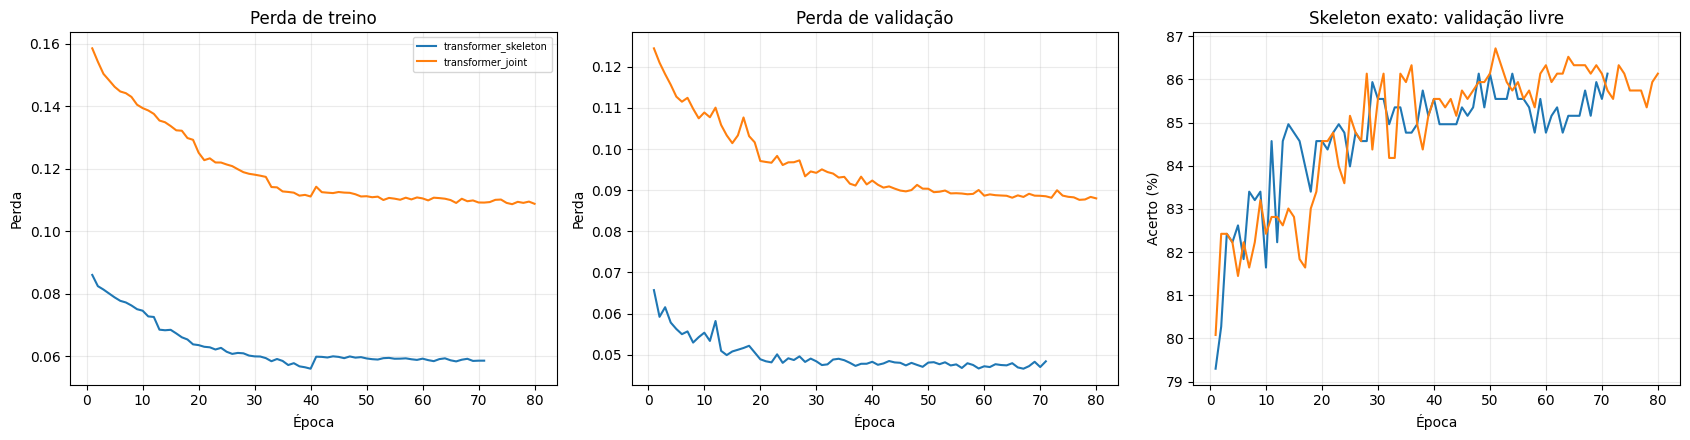

transformer_skeleton


,input_formula,target,predicted,valid,skeleton_exact,joint_exact
0,((x_0(t-11) + (((x_0(t-8) * x_0(t-12)) + x_0(t-12)) * x_0(t-1))) * (0.425209 + x_0(t-1))),s_0[t-11] + s_0[t-1] * s_0[t-11] + s_0[t-1] * s_0[t-12] + s_0[t-1] * s_0[t-1] * s_0[t-12] + s_0[t-1] * s_0[t-8] * s_0[t-12] + s_0[t-1] * s_0[t-1] * s_0[t-8] * s_0[t-12],s_0[t-1] * s_0[t-11] + s_0[t-1] * s_0[t-12] + s_0[t-1] * s_0[t-1] * s_0[t-12] + s_0[t-1] * s_0[t-8] * s_0[t-12] + s_0[t-1] * s_0[t-1] * s_0[t-8] * s_0[t-12],True,False,None
1,((x_0(t-11) * ((x_0(t-7) + (x_0(t-5) * x_0(t-12))) + (x_0(t-8) + x_0(t-7)))) * x_0(t-4)),s_0[t-4] * s_0[t-7] * s_0[t-11] + s_0[t-4] * s_0[t-8] * s_0[t-11] + s_0[t-4] * s_0[t-5] * s_0[t-11] * s_0[t-12],s_0[t-4] * s_0[t-7] * s_0[t-11] + s_0[t-4] * s_0[t-8] * s_0[t-11] + s_0[t-4] * s_0[t-11] * s_0[t-11] + s_0[t-4] * s_0[t-5] * s_0[t-11] * s_0[t-12],True,False,None
2,((x_0(t-6) * x_0(t-2)) + (x_0(t-6) * (x_0(t-4) + ((x_0(t-1) * x_0(t-10)) * -0.427521)))),s_0[t-2] * s_0[t-6] + s_0[t-4] * s_0[t-6] + s_0[t-1] * s_0[t-6] * s_0[t-10],s_0[t-2] * s_0[t-6] + s_0[t-4] * s_0[t-6] + s_0[t-1] * s_0[t-6] * s_0[t-10],True,True,None
3,((x_0(t-8) + (x_0(t-7) * x_0(t-7))) + ((x_0(t-10) + x_0(t-5)) * (x_0(t-6) * x_0(t-5)))),s_0[t-8] + s_0[t-7] * s_0[t-7] + s_0[t-5] * s_0[t-5] * s_0[t-6] + s_0[t-5] * s_0[t-6] * s_0[t-10],s_0[t-8] + s_0[t-7] * s_0[t-7] + s_0[t-5] * s_0[t-5] * s_0[t-6] + s_0[t-5] * s_0[t-6] * s_0[t-10],True,True,None
4,(x_0(t-7) * (x_0(t-6) * (-0.866491 + ((x_0(t-1) + (x_0(t-7) + x_0(t-2))) + x_0(t-1))))),s_0[t-6] * s_0[t-7] + s_0[t-1] * s_0[t-6] * s_0[t-7] + s_0[t-2] * s_0[t-6] * s_0[t-7] + s_0[t-6] * s_0[t-7] * s_0[t-7],s_0[t-6] * s_0[t-7] + s_0[t-1] * s_0[t-6] * s_0[t-7] + s_0[t-2] * s_0[t-6] * s_0[t-7] + s_0[t-6] * s_0[t-7] * s_0[t-7],True,True,None
5,(0.781478 + (((x_0(t-4) + (x_0(t-3) + x_0(t-1))) + (x_0(t-1) * x_0(t-1))) * x_0(t-2))),1 + s_0[t-1] * s_0[t-2] + s_0[t-2] * s_0[t-3] + s_0[t-2] * s_0[t-4] + s_0[t-1] * s_0[t-1] * s_0[t-2],1 + s_0[t-1] * s_0[t-2] + s_0[t-2] * s_0[t-3] + s_0[t-2] * s_0[t-4] + s_0[t-1] * s_0[t-1] * s_0[t-2],True,True,None
6,((x_0(t-9) + (-0.406079 * x_0(t-9))) + (((x_0(t-11) * x_0(t-2)) + x_0(t-11)) * x_0(t-8))),s_0[t-9] + s_0[t-8] * s_0[t-11] + s_0[t-2] * s_0[t-8] * s_0[t-11],s_0[t-9] + s_0[t-9] + s_0[t-8] * s_0[t-11] + s_0[t-2] * s_0[t-8] * s_0[t-11],False,False,None
7,(x_0(t-7) + (x_0(t-2) * (x_0(t-12) + ((x_0(t-8) + x_0(t-2)) + (x_0(t-10) + x_0(t-12)))))),s_0[t-7] + s_0[t-2] * s_0[t-2] + s_0[t-2] * s_0[t-8] + s_0[t-2] * s_0[t-10] + s_0[t-2] * s_0[t-12],s_0[t-7] + s_0[t-2] * s_0[t-2] + s_0[t-2] * s_0[t-8] + s_0[t-2] * s_0[t-10] + s_0[t-2] * s_0[t-12],True,True,None
8,(((x_0(t-6) + ((x_0(t-2) + (x_0(t-8) * x_0(t-7))) * x_0(t-10))) * x_0(t-1)) + x_0(t-7)),s_0[t-7] + s_0[t-1] * s_0[t-6] + s_0[t-1] * s_0[t-2] * s_0[t-10] + s_0[t-1] * s_0[t-7] * s_0[t-8] * s_0[t-10],s_0[t-7] + s_0[t-1] * s_0[t-6] + s_0[t-1] * s_0[t-2] * s_0[t-10] + s_0[t-1] * s_0[t-7] * s_0[t-8] * s_0[t-10],True,True,None
9,((((x_0(t-6) * x_0(t-4)) + x_0(t-12)) + x_0(t-9)) * ((x_0(t-4) * x_0(t-4)) + x_0(t-9))),s_0[t-9] * s_0[t-9] + s_0[t-9] * s_0[t-12] + s_0[t-4] * s_0[t-4] * s_0[t-9] + s_0[t-4] * s_0[t-4] * s_0[t-12] + s_0[t-4] * s_0[t-6] * s_0[t-9] + s_0[t-4] * s_0[t-4] * s_0[t-4] * s_0[t-6],s_0[t-9] * s_0[t-9] + s_0[t-9] * s_0[t-12] + s_0[t-4] * s_0[t-4] * s_0[t-6] + s_0[t-4] * s_0[t-4] * s_0[t-9] + s_0[t-4] * s_0[t-4] * s_0[t-6] + s_0[t-4] * s_0[t-4] * s_0[t-6],False,False,None


,group,value,count,skeleton_exact
0,operator_count,5,45,0.8444
1,operator_count,6,3955,0.8174
2,degree,1,134,0.9851
3,degree,2,981,0.8400
4,degree,3,1453,0.8011
5,degree,4,1432,0.8038
6,parameter_count,0,2096,0.8211
7,parameter_count,1,1431,0.8176
8,parameter_count,2,404,0.8094
9,parameter_count,3,63,0.7619


transformer_joint


,input_formula,target,predicted,valid,skeleton_exact,joint_exact
0,((x_0(t-11) + (((x_0(t-8) * x_0(t-12)) + x_0(t-12)) * x_0(t-1))) * (0.425209 + x_0(t-1))),(0.4252)*s_0[t-11] + (1)*s_0[t-1] * s_0[t-11] + (0.4252)*s_0[t-1] * s_0[t-12] + (1)*s_0[t-1] * s_0[t-1] * s_0[t-12] + (0.4252)*s_0[t-1] * s_0[t-8] * s_0[t-12] + (1)*s_0[t-1] * s_0[t-1] * s_0[t-8] * s_0[t-12],(0.4415)*s_0[t-11] + (0.976)*s_0[t-1] * s_0[t-12] + (1.147)*s_0[t-1] * s_0[t-1] * s_0[t-12] + (1.024)*s_0[t-1] * s_0[t-8] * s_0[t-12] + (1.103)*s_0[t-1] * s_0[t-1] * s_0[t-8] * s_0[t-12],True,False,False
1,((x_0(t-11) * ((x_0(t-7) + (x_0(t-5) * x_0(t-12))) + (x_0(t-8) + x_0(t-7)))) * x_0(t-4)),(2)*s_0[t-4] * s_0[t-7] * s_0[t-11] + (1)*s_0[t-4] * s_0[t-8] * s_0[t-11] + (1)*s_0[t-4] * s_0[t-5] * s_0[t-11] * s_0[t-12],(1.124)*s_0[t-4] * s_0[t-7] * s_0[t-11] + (1.111)*s_0[t-4] * s_0[t-8] * s_0[t-11] + (0.9565)*s_0[t-4] * s_0[t-11] * s_0[t-11] + (0.9869)*s_0[t-4] * s_0[t-5] * s_0[t-11] * s_0[t-12],True,False,False
2,((x_0(t-6) * x_0(t-2)) + (x_0(t-6) * (x_0(t-4) + ((x_0(t-1) * x_0(t-10)) * -0.427521)))),(1)*s_0[t-2] * s_0[t-6] + (1)*s_0[t-4] * s_0[t-6] + (-0.4275)*s_0[t-1] * s_0[t-6] * s_0[t-10],(1.013)*s_0[t-2] * s_0[t-6] + (1.058)*s_0[t-4] * s_0[t-6] + (-0.4721)*s_0[t-1] * s_0[t-6] * s_0[t-10],True,True,False
3,((x_0(t-8) + (x_0(t-7) * x_0(t-7))) + ((x_0(t-10) + x_0(t-5)) * (x_0(t-6) * x_0(t-5)))),(1)*s_0[t-8] + (1)*s_0[t-7] * s_0[t-7] + (1)*s_0[t-5] * s_0[t-5] * s_0[t-6] + (1)*s_0[t-5] * s_0[t-6] * s_0[t-10],(0.9635)*s_0[t-8] + (0.8971)*s_0[t-7] * s_0[t-7] + (0.9582)*s_0[t-5] * s_0[t-5] * s_0[t-6] + (0.9872)*s_0[t-5] * s_0[t-6] * s_0[t-10],True,True,False
4,(x_0(t-7) * (x_0(t-6) * (-0.866491 + ((x_0(t-1) + (x_0(t-7) + x_0(t-2))) + x_0(t-1))))),(-0.8665)*s_0[t-6] * s_0[t-7] + (2)*s_0[t-1] * s_0[t-6] * s_0[t-7] + (1)*s_0[t-2] * s_0[t-6] * s_0[t-7] + (1)*s_0[t-6] * s_0[t-7] * s_0[t-7],(-0.8145)*s_0[t-6] * s_0[t-7] + (1.326)*s_0[t-1] * s_0[t-6] * s_0[t-7] + (1.159)*s_0[t-2] * s_0[t-6] * s_0[t-7] + (1.027)*s_0[t-6] * s_0[t-7] * s_0[t-7],True,True,False
5,(0.781478 + (((x_0(t-4) + (x_0(t-3) + x_0(t-1))) + (x_0(t-1) * x_0(t-1))) * x_0(t-2))),(0.7815)*1 + (1)*s_0[t-1] * s_0[t-2] + (1)*s_0[t-2] * s_0[t-3] + (1)*s_0[t-2] * s_0[t-4] + (1)*s_0[t-1] * s_0[t-1] * s_0[t-2],(0.6975)*1 + (0.9772)*s_0[t-1] * s_0[t-2] + (1.026)*s_0[t-2] * s_0[t-3] + (1.132)*s_0[t-2] * s_0[t-4] + (1.056)*s_0[t-1] * s_0[t-1] * s_0[t-2],True,True,False
6,((x_0(t-9) + (-0.406079 * x_0(t-9))) + (((x_0(t-11) * x_0(t-2)) + x_0(t-11)) * x_0(t-8))),(0.5939)*s_0[t-9] + (1)*s_0[t-8] * s_0[t-11] + (1)*s_0[t-2] * s_0[t-8] * s_0[t-11],(0.3037)*s_0[t-9] + (0.8847)*s_0[t-8] * s_0[t-11] + (1.074)*s_0[t-2] * s_0[t-8] * s_0[t-11],True,True,False
7,(x_0(t-7) + (x_0(t-2) * (x_0(t-12) + ((x_0(t-8) + x_0(t-2)) + (x_0(t-10) + x_0(t-12)))))),(1)*s_0[t-7] + (1)*s_0[t-2] * s_0[t-2] + (1)*s_0[t-2] * s_0[t-8] + (1)*s_0[t-2] * s_0[t-10] + (2)*s_0[t-2] * s_0[t-12],(0.9949)*s_0[t-7] + (0.9336)*s_0[t-2] * s_0[t-2] + (1.067)*s_0[t-2] * s_0[t-8] + (1.241)*s_0[t-2] * s_0[t-10] + (1.322)*s_0[t-2] * s_0[t-12],True,True,False
8,((((x_0(t-6) * x_0(t-4)) + x_0(t-12)) + x_0(t-9)) * ((x_0(t-4) * x_0(t-4)) + x_0(t-9))),(1)*s_0[t-9] * s_0[t-9] + (1)*s_0[t-9] * s_0[t-12] + (1)*s_0[t-4] * s_0[t-4] * s_0[t-9] + (1)*s_0[t-4] * s_0[t-4] * s_0[t-12] + (1)*s_0[t-4] * s_0[t-6] * s_0[t-9] + (1)*s_0[t-4] * s_0[t-4] * s_0[t-4] * s_0[t-6],(1.131)*s_0[t-9] * s_0[t-9] + (0.9922)*s_0[t-9] * s_0[t-12] + (1.001)*s_0[t-4] * s_0[t-4] * s_0[t-6] + (1.232)*s_0[t-4] * s_0[t-9] * s_0[t-12] + (1.004)*s_0[t-4] * s_0[t-4] * s_0[t-4] * s_0[t-6] + (1.083)*s_0[t-4] * s_0[t-4] * s_0[t-6] * s_0[t-9],True,False,False
9,((x_0(t-6) + -0.702305) * (((-0.348713 * x_0(t-10)) + x_0(t-11)) + (x_0(t-4) * x_0(t-4)))),(0.2449)*s_0[t-10] + (-0.7023)*s_0[t-11] + (-0.7023)*s_0[t-4] * s_0[t-4] + (-0.3487)*s_0[t-6] * s_0[t-10] + (1)*s_0[t-6] * s_0[t-11] + (1)*s_0[t-4] * s_0[t-4] * s_0[t-6],(-0.6521)*s_0[t-10] + (-0.5656)*s_0[t-11] + (-0.3021)*s_0[t-4] * s_0[t-6] + (-0.4761)*s_0[t-4] * s_0[t-10] +

,group,value,count,skeleton_exact
0,operator_count,5,45,0.8222
1,operator_count,6,3955,0.8288
2,degree,1,134,0.9776
3,degree,2,981,0.8451
4,degree,3,1453,0.8059
5,degree,4,1432,0.8268
6,parameter_count,0,2096,0.8359
7,parameter_count,1,1431,0.8239
8,parameter_count,2,404,0.8243
9,parameter_count,3,63,0.7460


In [5]:
final_status=finish_study(EXPERIMENT_CONFIG,RUN_DIR)
results=final_status['variants']
summary_rows=[]
for name,result in results.items():
    metrics=result['test']
    summary_rows.append({'Modelo':name,'Parâmetros':result['parameters'],
        'Melhor época':result['best_epoch'],'Épocas executadas':len(result['history']),
        'Skeleton exato (%)':100*metrics['skeleton_exact'],
        'F1 termos':metrics['term_f1'],'Validade (%)':100*metrics['valid_rate'],
        'Expressão conjunta correta (%)':100*metrics['joint_exact'] if metrics['joint_exact'] is not None else None,
        'RMSE coeficientes união':metrics['coefficient_union_rmse'],
        'MAE coeficientes correspondentes':metrics['coefficient_matched_mae'],
        'Coeficientes correspondentes':metrics['matched_coefficient_count'],
        'Tempo treino e avaliação (min)':result['training_seconds']/60,
        'Tempo geração livre teste (s)':metrics['seconds']})
summary_df=pd.DataFrame(summary_rows)
display(summary_df.round(4))
fig,axes=plt.subplots(1,3,figsize=(17,4.5))
for name,result in results.items():
    history=pd.DataFrame(result['history'])
    axes[0].plot(history['epoch'],history['train_loss'],label=name)
    axes[1].plot(history['epoch'],history['validation_loss'],label=name)
    axes[2].plot(history['epoch'],100*history['validation_greedy_exact'],label=name)
axes[0].set(title='Perda de treino',xlabel='Época',ylabel='Perda')
axes[1].set(title='Perda de validação',xlabel='Época',ylabel='Perda')
axes[2].set(title='Skeleton exato: validação livre',xlabel='Época',ylabel='Acerto (%)')
for ax in axes:ax.grid(alpha=.25)
axes[0].legend(fontsize=7)
fig.tight_layout();plt.show()
for name,result in results.items():
    print(name)
    display(pd.DataFrame(result['examples']))
    display(pd.DataFrame(result['groups']).round(4))

**O que foi feito:** mostramos as m?tricas, curvas e erros dos modelos refinados. A compara??o abaixo mostra tamb?m o resultado anterior nas mesmas parti??es.


In [6]:
from tsfmxai.symbolic_regression.canonical_training import read_status
baseline=read_status(ROOT/'outputs/canonicalization/encoder_decoder_20261029_01')
assert dataset_summary['fingerprint']==baseline['dataset']['fingerprint']
comparison=[]
for name in ('transformer_skeleton','transformer_joint'):
    before=baseline['variants'][name]['test']; after=results[name]['test']
    comparison.append({'Modelo':name,'Antes: skeleton exato (%)':100*before['skeleton_exact'],
        'Agora: skeleton exato (%)':100*after['skeleton_exact'],
        'Mudan?a (p.p.)':100*(after['skeleton_exact']-before['skeleton_exact']),
        'Antes: F1 termos':before['term_f1'],'Agora: F1 termos':after['term_f1'],
        'Antes: MAE coef. correspondentes':before['coefficient_matched_mae'],
        'Agora: MAE coef. correspondentes':after['coefficient_matched_mae'],
        'Antes: express?o completa (%)':None if before['joint_exact'] is None else 100*before['joint_exact'],
        'Agora: express?o completa (%)':None if after['joint_exact'] is None else 100*after['joint_exact']})
display(pd.DataFrame(comparison).round(4))


,Modelo,Antes: skeleton exato (%),Agora: skeleton exato (%),Mudan?a (p.p.),Antes: F1 termos,Agora: F1 termos,Antes: MAE coef. correspondentes,Agora: MAE coef. correspondentes,Antes: express?o completa (%),Agora: express?o completa (%)
0,transformer_skeleton,74.350,81.775,7.425,0.9421,0.9630,NaN,NaN,NaN,NaN
1,transformer_joint,73.075,82.875,9.800,0.9437,0.9646,0.1494,0.1317,0.025,0.1


**O que foi feito:** comparamos os dois treinamentos sobre os mesmos exemplos, com o mesmo fingerprint. Os resultados servem para orientar o desenvolvimento; o teste j? foi consultado antes deste refinamento.


## 7. Registro completo do experimento executado

Configura??o, proveni?ncia, seeds, m?tricas, resumo cient?fico e comando de reprodu??o ficam registrados nesta c?lula.


In [7]:
source_files=[
 'src/tsfmxai/symbolic_regression/canonical_data.py',
 'src/tsfmxai/symbolic_regression/canonical_models.py',
 'src/tsfmxai/symbolic_regression/canonical_training.py',
 'src/tsfmxai/generators/combinatorial_expression.py',
 'src/tsfmxai/representations/canonical_polynomial.py',
]
best=summary_df.sort_values('Skeleton exato (%)',ascending=False).iloc[0]
record={
 'question':'Does continuing the two Transformer models with smaller learning rate and higher coefficient weight improve canonical AST decoding?',
 'configuration':EXPERIMENT_CONFIG,
 'provenance':{'source_sha256':EXPERIMENT_CONFIG['implementation_sha256'],
    'python':platform.python_version(),'torch':torch.__version__,'numpy':np.__version__,
    'device':'cpu','cpu_threads':torch.get_num_threads(),
    'dataset':dataset_summary,'run_directory':str(RUN_DIR),
    'source_rng':'CombinatorialTreeSampler with derive_sample_seed(data_seed,index)',
    'split':'SHA256(split_seed|SHA256(skeleton)); all equivalent supports stay together',
    'training_rng':'torch fork_rng and fixed seed; dedicated DataLoader shuffle generator',
    'references':['vaswani2017attention','tai2015treelstm','luong2015attention'],
 },
 'metrics':summary_df.where(pd.notna(summary_df),None).to_dict('records'),
 'checkpoints':{name:value['checkpoint'] for name,value in results.items()},
 'comparison_to_previous':comparison,
 'scientific_summary':f"Best observed skeleton exact match: {best['Modelo']} = {best['Skeleton exato (%)']:.2f}%. The earlier test was inspected before refinement; treat this comparison as development diagnostics.",
 'reproduction':
  '.venv/Scripts/python.exe scripts/execute_notebook_background.py '
  '--notebook experiments/canonicalization/encoder_decoder_refinement/4_transformer_refinement.ipynb '
  '--run-dir outputs/canonicalization/encoder_decoder_refinement_20261030_01',
 'resume':'Repeat the command with the same configuration and run directory; completed variants are loaded and unfinished variants resume from last.pt.',
}
from pprint import pprint
pprint(record,sort_dicts=False)

{'question': 'Does continuing the two Transformer models with smaller learning '
             'rate and higher coefficient weight improve canonical AST '
             'decoding?',
 'configuration': {'generator': {'minimum_operators': 1,
                                 'maximum_operators': 6,
                                 'num_series': 1,
                                 'minimum_lag': 1,
                                 'maximum_lag': 12,
                                 'max_degree': 4,
                                 'minimum_parameter_magnitude': 0.05,
                                 'maximum_parameter_magnitude': 0.9},
                   'dataset_sizes': {'train': 40000,
                                     'validation': 4000,
                                     'test': 4000},
                   'data_seed': 20261029,
                   'split_seed': 20261030,
                   'training_seed': 20261031,
                   'max_decode_steps': 64,
                   'batch_s

**O que foi feito:** salvamos o registro científico no notebook. A reprodução com o mesmo diretório retoma checkpoints; uma execução independente deve usar outro diretório e seeds explicitamente escolhidas.